<a href="https://colab.research.google.com/github/sriharikk/FDVA_241501093/blob/main/Exp3_fdva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Initial Data Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            10 non-null     object 
 1   Gender             9 non-null      object 
 2   Married            9 non-null      object 
 3   Dependents         9 non-null      object 
 4   Education          10 non-null     object 
 5   Self_Employed      9 non-null      object 
 6   ApplicantIncome    10 non-null     int64  
 7   CoapplicantIncome  10 non-null     int64  
 8   LoanAmount         8 non-null      float64
 9   Loan_Amount_Term   9 non-null      float64
 10  Credit_History     9 non-null      float64
 11  Property_Area      10 non-null     object 
 12  Loan_Status        10 non-null     object 
dtypes: float64(3), int64(2), object(8)
memory usage: 1.1+ KB

First Five Rows:
  Loan_ID  Gender Married Dependents     Education Self_Employed  \
0    L0

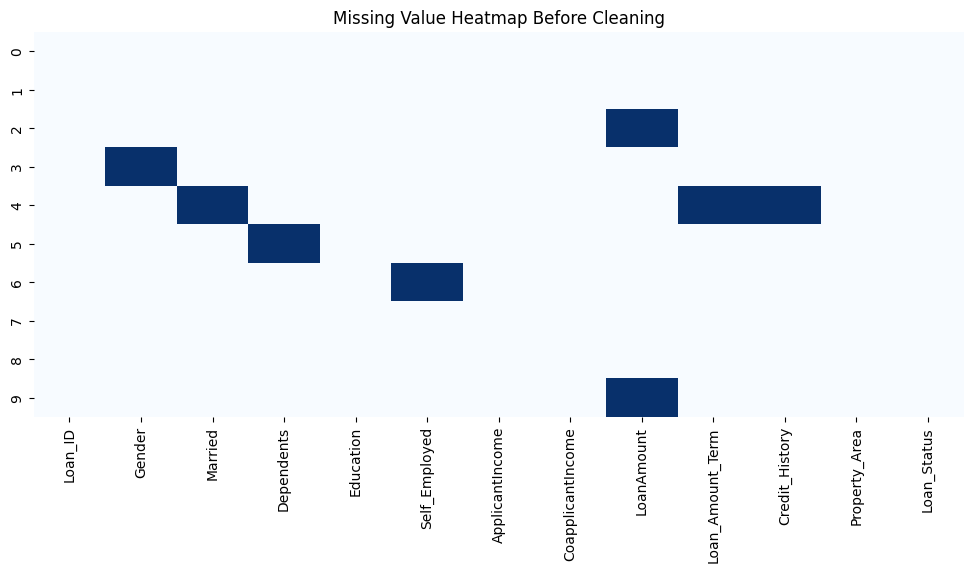


Removed 0 duplicate rows.

Min-Max Normalization completed.
Standardization completed.

Cleaned Data Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            10 non-null     object 
 1   Gender             10 non-null     object 
 2   Married            10 non-null     object 
 3   Dependents         10 non-null     int64  
 4   Education          10 non-null     object 
 5   Self_Employed      10 non-null     object 
 6   ApplicantIncome    10 non-null     float64
 7   CoapplicantIncome  10 non-null     float64
 8   LoanAmount         10 non-null     float64
 9   Loan_Amount_Term   10 non-null     float64
 10  Credit_History     10 non-null     float64
 11  Property_Area      10 non-null     object 
 12  Loan_Status        10 non-null     object 
dtypes: float64(5), int64(1), object(7)
memory usage: 1.1+ KB

Firs

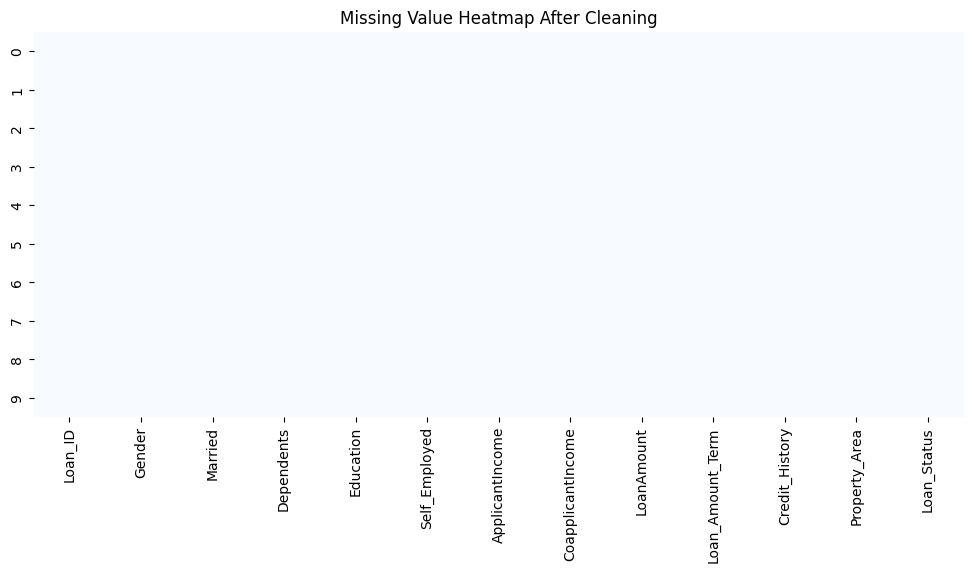

In [9]:

# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Create a sample Loan Prediction dataset
data = {
    'Loan_ID': ['L001', 'L002', 'L003', 'L004', 'L005',
                'L006', 'L007', 'L008', 'L009', 'L010'],
    'Gender': ['Male', 'Female', 'Male', np.nan, 'Male',
               'Female', 'Male', 'Female', 'Male', 'Male'],
    'Married': ['Yes', 'No', 'Yes', 'Yes', np.nan,
                'No', 'Yes', 'Yes', 'No', 'Yes'],
    'Dependents': ['0', '1', '0', '2', '3+', np.nan,
                   '1', '0', '2', '0'],
    'Education': ['Graduate', 'Graduate', 'Not Graduate',
                  'Graduate', 'Graduate', 'Not Graduate',
                  'Graduate', 'Graduate', 'Not Graduate', 'Graduate'],
    'Self_Employed': ['No', 'No', 'Yes', 'No', 'No',
                      'Yes', np.nan, 'No', 'No', 'Yes'],
    'ApplicantIncome': [5000, 3000, 4000, 6000, 10000,
                        2500, 7000, 3500, 4500, 8000],
    'CoapplicantIncome': [0, 1500, 2000, 0, 2500,
                          1000, 3000, 500, 0, 1500],
    'LoanAmount': [120, 100, np.nan, 150, 200,
                   80, 160, 90, 110, np.nan],
    'Loan_Amount_Term': [360, 360, 180, 360, np.nan,
                         360, 360, 180, 360, 360],
    'Credit_History': [1, 1, 0, 1, np.nan,
                       0, 1, 1, 1, 0],
    'Property_Area': ['Urban', 'Rural', 'Semiurban', 'Urban',
                      'Rural', 'Semiurban', 'Urban', 'Rural',
                      'Semiurban', 'Urban'],
    'Loan_Status': ['Y', 'N', 'Y', 'Y', 'N',
                    'N', 'Y', 'N', 'Y', 'Y']
}

df = pd.DataFrame(data)

# 1. Display initial data information
print("Initial Data Overview:")
df.info()

print("\nFirst Five Rows:")
print(df.head())

# 2. Handle missing values
print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="Blues")
plt.title("Missing Value Heatmap Before Cleaning")
plt.show()

# Fill categorical missing values using mode
categorical_cols = [
    'Gender', 'Married', 'Dependents', 'Self_Employed'
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill numerical missing values using median
df['LoanAmount'] = df['LoanAmount'].fillna(
    df['LoanAmount'].median()
)

# Fill loan term and credit history using mode
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(
    df['Loan_Amount_Term'].mode()[0]
)

df['Credit_History'] = df['Credit_History'].fillna(
    df['Credit_History'].mode()[0]
)

# 3. Remove duplicate rows
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)

print(f"\nRemoved {initial_rows - df.shape[0]} duplicate rows.")

# 4. Convert Dependents to numeric
df['Dependents'] = (
    df['Dependents'].replace('3+', '3').astype(int)
)

# 5. Ensure categorical consistency
consistency_cols = [
    'Gender', 'Married', 'Education',
    'Self_Employed', 'Property_Area'
]

for col in consistency_cols:
    df[col] = df[col].str.strip().str.capitalize()

# 6. Normalize numerical columns using MinMaxScaler
scale_cols = [
    'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount'
]

min_max_scaler = MinMaxScaler()
df[scale_cols] = min_max_scaler.fit_transform(df[scale_cols])

print("\nMin-Max Normalization completed.")

# 7. Standardize Credit_History using StandardScaler
standard_scaler = StandardScaler()

df[['Credit_History']] = standard_scaler.fit_transform(
    df[['Credit_History']]
)

print("Standardization completed.")

# 8. Display final cleaned data
print("\nCleaned Data Summary:")
df.info()

print("\nFirst Five Rows of Cleaned Data:")
print(df.head())

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:")
print(df.shape)

# 9. Visualize missing values after cleaning
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="Blues")
plt.title("Missing Value Heatmap After Cleaning")
plt.show()